In [55]:
import numpy as np
import matplotlib.pylab as plt
import math
import pandas as pd
import seaborn as sns
import os
from matplotlib import rcParams
import pickle
from scipy.stats import kurtosis
from sklearn.covariance import LedoitWolf
from sklearn.mixture import GaussianMixture
from Functions.Graphs import *
from Functions.Utils import *
import pickle


In [47]:
def fault_indices(Z, groups=('BPFO', 'BPFI', 'BSF', 'FTF'), how='mean_pos'):
    FI = {}
    for g in groups:
        Zg = Z[[c for c in Z.columns if c.startswith(g)]]
        if how == 'mean':        # current FI: equal weights
            FI[g] = Zg.mean(axis=1)
        elif how == 'mean_pos':  # one-sided: only rises above the healthy baseline count
            FI[g] = Zg.clip(lower=0).mean(axis=1)
        elif how == 'rms_pos':   # rewards a few strong harmonics more than many weak ones
            FI[g] = np.sqrt((Zg.clip(lower=0)**2).mean(axis=1))
    return pd.DataFrame(FI, index=Z.index)

def analyze(path,alpha=0.3):
    Z = pd.read_csv(path)
    Z = exponential_moving_average_df(Z**2,alpha)
    df = fault_indices(Z, groups=('BPFO', 'BPFI', 'BSF', 'FTF'), how='mean_pos')
    PlotFramesPLT([df])


In [94]:
inDir =r'Dataset\DSI\Vertical'
outDir = r'Dataset\DSI2\Vertical'
brngs = os.listdir(inDir)
for brng in brngs:
    bPath = os.path.join(inDir,brng)
    outFile = os.path.join(outDir,brng)
    Z = pd.read_csv(bPath) ** 1
    Z = exponential_moving_average_df(df=Z,alpha=0.2)
    df = fault_indices(Z, groups=('BPFO', 'BPFI', 'BSF', 'FTF'), how='mean_pos')
    df.to_csv(outFile,index=False)

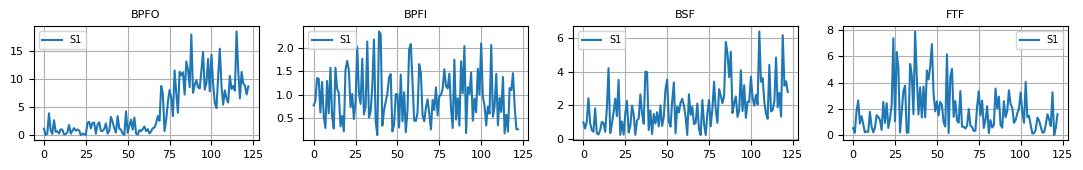

In [46]:
brng = 'Bearing1_1.csv'
path = f'Dataset\DSI\Horizontal\{brng}'
analyze(path,alpha=0.1)


In [50]:
Z = pd.read_csv(path)
Z = exponential_moving_average_df(df=Z**2,alpha=0.2)
df = fault_indices(Z, groups=('BPFO', 'BPFI', 'BSF', 'FTF'), how='mean_pos')
df.to_csv('testRS.csv',index=False)

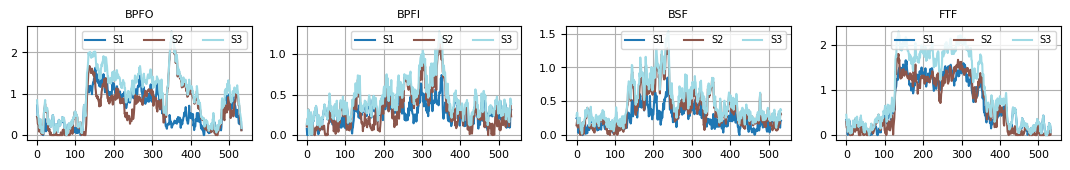

In [97]:
brng = 'Bearing2_3.csv'
path = f'Dataset\DSI2\Horizontal\{brng}'
df1 = pd.read_csv(path)
path = f'Dataset\DSI2\Vertical\{brng}'
df2 = pd.read_csv(path)
df3 = np.sqrt((df1**2)+(df2**2))
PlotFramesPLT([df1,df2,df3])

